<a href="https://colab.research.google.com/github/VictorSantos117/Minera-o_dados/blob/main/Minera%C3%A7%C3%A3o_produtos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import warnings
import logging
import os
import sys

# 1. Ignorar todos os warnings no Python de forma absoluta
warnings.filterwarnings('ignore')

# 2. Sobrescrever a função showwarning para garantir que absolutamente nada seja impresso no stderr
def custom_showwarning(*args, **kwargs):
    pass
warnings.showwarning = custom_showwarning

# 3. Silenciar logs de depuração do Jupyter, IPKernel e matplotlib
logging.getLogger('jupyter_client').setLevel(logging.ERROR)
logging.getLogger('IPKernelApp').setLevel(logging.ERROR)
logging.getLogger('matplotlib').setLevel(logging.ERROR)

# 4. Desativar warnings de ambiente de subprocessos
os.environ['PYTHONWARNINGS'] = 'ignore'

print('Filtro absoluto ativado! Todos os warnings do sistema foram completamente bloqueados.')

Filtro absoluto ativado! Todos os warnings do sistema foram completamente bloqueados.


In [7]:
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

import pandas as pd
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

# ==========================================
# 1. CARREGAMENTO E PREPARAÇÃO DO DATASET
# ==========================================
df_raw = pd.read_csv('Groceries_dataset.csv')

# Agrupando os itens pelo cliente (Member_number) e data (Date) para formar as transações
transacoes_groceries = df_raw.groupby(['Member_number', 'Date'])['itemDescription'].apply(list).tolist()

print(f"Total de transações de compras carregadas: {len(transacoes_groceries)}")

# ==========================================
# 2. PRÉ-PROCESSAMENTO (TransactionEncoder)
# ==========================================
# Filtramos carrinhos vazios ou unitários se quisermos regras mais ricas
transacoes_filtradas = [t for t in transacoes_groceries if len(t) >= 2]
print(f"Transações com 2 ou mais itens: {len(transacoes_filtradas)}")

# Converte a lista de transações em uma matriz One-Hot (True/False) exigida pelo Apriori
te = TransactionEncoder()
te_ary = te.fit(transacoes_filtradas).transform(transacoes_filtradas)
df_encoded = pd.DataFrame(te_ary, columns=te.columns_)

# ==========================================
# 3. APLICAÇÃO DO ALGORITMO APRIORI
# ==========================================
# Ajustado o suporte mínimo para 0.001 (0.1%) para encontrar regras consistentes
frequent_itemsets = apriori(df_encoded, min_support=0.001, use_colnames=True)

print(f"\nConjuntos frequentes encontrados: {len(frequent_itemsets)}")

# ==========================================
# 4. GERAÇÃO DAS REGRAS DE ASSOCIAÇÃO
# ==========================================
regras = association_rules(frequent_itemsets, metric="lift", min_threshold=1.0)

# Ordenando por Lift e Confiança
regras_ordenadas = ...

# Se houver regras, formatar e mostrar as top 10
if not regras.empty:
    regras_ordenadas = regras.sort_values(by=['lift', 'confidence'], ascending=False)
    print("\n--- REGRAS DE ASSOCIAÇÃO DO GROCERIES ---")
    resultado_final = regras_ordenadas[['antecedents', 'consequents', 'support', 'confidence', 'lift']]
    print(resultado_final.head(10).to_string(index=False))
else:
    print("Nenhuma regra encontrada com a configuração atual.")

Total de transações de compras carregadas: 14963
Transações com 2 ou mais itens: 14963

Conjuntos frequentes encontrados: 750

--- REGRAS DE ASSOCIAÇÃO DO GROCERIES ---
          antecedents           consequents  support  confidence     lift
 (yogurt, whole milk)             (sausage) 0.001470    0.131737 2.182917
            (sausage)  (yogurt, whole milk) 0.001470    0.024363 2.182917
(sausage, whole milk)              (yogurt) 0.001470    0.164179 1.911760
             (yogurt) (sausage, whole milk) 0.001470    0.017121 1.911760
(specialty chocolate)        (citrus fruit) 0.001403    0.087866 1.653762
       (citrus fruit) (specialty chocolate) 0.001403    0.026415 1.653762
    (sausage, yogurt)          (whole milk) 0.001470    0.255814 1.619866
         (whole milk)     (sausage, yogurt) 0.001470    0.009310 1.619866
     (tropical fruit)               (flour) 0.001069    0.015779 1.617141
              (flour)      (tropical fruit) 0.001069    0.109589 1.617141


In [8]:
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

import pandas as pd
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules


traducao_itens = {
    'whole milk': 'leite integral',
    'yogurt': 'iogurte',
    'sausage': 'salsicha',
    'soda': 'refrigerante',
    'rolls/buns': 'pãezinhos',
    'other vegetables': 'outros vegetais',
    'citrus fruit': 'frutas cítricas',
    'specialty chocolate': 'chocolate especial',
    'tropical fruit': 'frutas tropicais',
    'flour': 'farinha',
    'beef': 'carne bovina',
    'pastry': 'folhados/doces',
    'root vegetables': 'vegetais de raiz',
    'canned beer': 'cerveja em lata',
    'bottled water': 'água engarrafada',
    'bottled beer': 'cerveja de garrafa',
    'shopping bags': 'sacolas de compras',
    'brown bread': 'pão preto/integral',
    'whipped/sour cream': 'creme de leite/chantilly',
    'newspapers': 'jornais',
    'domestic eggs': 'ovos caipiras',
    'margarine': 'margarina',
    'pip fruit': 'frutas de semente (maçã/pera)',
    'fruit/vegetable juice': 'suco de fruta/vegetal',
    'frankfurter': 'salsicha alemã',
    'pork': 'carne de porco',
    'curd': 'coalhada',
    'rolls/buns': 'pãezinhos/bisnagas'
}

# Recarregar o dataset para garantir consistência
df_raw = pd.read_csv('Groceries_dataset.csv')

# Substituir os nomes dos produtos usando o dicionário (os não mapeados permanecerão iguais)
df_raw['itemDescription'] = df_raw['itemDescription'].replace(traducao_itens)

# Agrupar novamente em transações com os itens já traduzidos
transacoes_groceries = df_raw.groupby(['Member_number', 'Date'])['itemDescription'].apply(list).tolist()
transacoes_filtradas = [t for t in transacoes_groceries if len(t) >= 2]

# One-Hot Encoding
te = TransactionEncoder()
te_ary = te.fit(transacoes_filtradas).transform(transacoes_filtradas)
df_encoded = pd.DataFrame(te_ary, columns=te.columns_)

# Apriori
frequent_itemsets = apriori(df_encoded, min_support=0.001, use_colnames=True)
regras = association_rules(frequent_itemsets, metric="lift", min_threshold=1.0)

# Se houver regras, formatar e mostrar as top 10 traduzidas
if not regras.empty:
    regras_ordenadas = regras.sort_values(by=['lift', 'confidence'], ascending=False)
    print("\n--- REGRAS DE ASSOCIAÇÃO DO GROCERIES (TRADUZIDAS) ---")
    resultado_final = regras_ordenadas[['antecedents', 'consequents', 'support', 'confidence', 'lift']]
    print(resultado_final.head(10).to_string(index=False))
else:
    print("Nenhuma regra encontrada com a configuração atual.")


--- REGRAS DE ASSOCIAÇÃO DO GROCERIES (TRADUZIDAS) ---
               antecedents                consequents  support  confidence     lift
 (leite integral, iogurte)                 (salsicha) 0.001470    0.131737 2.182917
                (salsicha)  (leite integral, iogurte) 0.001470    0.024363 2.182917
(salsicha, leite integral)                  (iogurte) 0.001470    0.164179 1.911760
                 (iogurte) (salsicha, leite integral) 0.001470    0.017121 1.911760
      (chocolate especial)          (frutas cítricas) 0.001403    0.087866 1.653762
         (frutas cítricas)       (chocolate especial) 0.001403    0.026415 1.653762
       (salsicha, iogurte)           (leite integral) 0.001470    0.255814 1.619866
          (leite integral)        (salsicha, iogurte) 0.001470    0.009310 1.619866
        (frutas tropicais)                  (farinha) 0.001069    0.015779 1.617141
                 (farinha)         (frutas tropicais) 0.001069    0.109589 1.617141


In [9]:
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

# Vamos definir uma lista de itens dominantes para excluir da visualização das regras
itens_para_excluir = {'leite integral', 'iogurte', 'salsicha', 'salsicha alemã'}

# Filtrar regras que NÃO contenham esses produtos dominantes nem no antecedente e nem no consequente
regras_filtradas = regras_ordenadas[
    ~regras_ordenadas['antecedents'].apply(lambda x: any(item in itens_para_excluir for item in x)) &
    ~regras_ordenadas['consequents'].apply(lambda x: any(item in itens_para_excluir for item in x))
]

print("--- OUTRAS ASSOCIAÇÕES DE PRODUTOS (SEM LEITE, IOGURTE OU SALSICHA) ---")
if not regras_filtradas.empty:
    resultado_alternativo = regras_filtradas[['antecedents', 'consequents', 'support', 'confidence', 'lift']]
    display(resultado_alternativo.head(10))
else:
    print("Nenhuma regra encontrada sem os itens dominantes. Vamos reduzir ligeiramente o suporte mínimo para encontrar mais variedade.")

--- OUTRAS ASSOCIAÇÕES DE PRODUTOS (SEM LEITE, IOGURTE OU SALSICHA) ---


,antecedents,consequents,support,confidence,lift
76,(chocolate especial),(frutas cítricas),0.001403,0.087866,1.653762
77,(frutas cítricas),(chocolate especial),0.001403,0.026415,1.653762
108,(frutas tropicais),(farinha),0.001069,0.015779,1.617141
109,(farinha),(frutas tropicais),0.001069,0.109589,1.617141
110,(napkins),(folhados/doces),0.001738,0.078550,1.518529
111,(folhados/doces),(napkins),0.001738,0.033592,1.518529
184,(processed cheese),(vegetais de raiz),0.001069,0.105263,1.513019
185,(vegetais de raiz),(processed cheese),0.001069,0.015370,1.513019
132,(frutas de semente (maçã/pera)),(hard cheese),0.001069,0.021798,1.482586
133,(hard cheese),(frutas de semente (maçã/pera)),0.001069,0.072727,1.482586


In [10]:
# Caso queiramos explorar ainda mais fundo, vamos recalcular o Apriori com suporte menor e removendo os dominantes direto no dataset
df_alternativo = df_raw[~df_raw['itemDescription'].isin(itens_para_excluir)]

transacoes_alt = df_alternativo.groupby(['Member_number', 'Date'])['itemDescription'].apply(list).tolist()
transacoes_alt_filtradas = [t for t in transacoes_alt if len(t) >= 2]

te_alt = TransactionEncoder()
te_ary_alt = te_alt.fit(transacoes_alt_filtradas).transform(transacoes_alt_filtradas)
df_encoded_alt = pd.DataFrame(te_ary_alt, columns=te_alt.columns_)

# Usando um suporte mínimo ligeiramente menor para capturar relações entre itens menos frequentes
frequent_itemsets_alt = apriori(df_encoded_alt, min_support=0.0005, use_colnames=True)
regras_alt = association_rules(frequent_itemsets_alt, metric="lift", min_threshold=1.1)

if not regras_alt.empty:
    regras_alt_ordenadas = regras_alt.sort_values(by=['lift', 'confidence'], ascending=False)
    print("\n--- ASSOCIAÇÕES DE PRODUTOS ALTERNATIVOS (MIN SUPORTE: 0.0005) ---")
    display(regras_alt_ordenadas[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(10))
else:
    print("Sem regras adicionais encontradas.")


--- ASSOCIAÇÕES DE PRODUTOS ALTERNATIVOS (MIN SUPORTE: 0.0005) ---


,antecedents,consequents,support,confidence,lift
294,(ham),(pickled vegetables),0.000652,0.034043,3.315096
295,(pickled vegetables),(ham),0.000652,0.063492,3.315096
310,(herbs),(oil),0.000570,0.047297,2.763514
311,(oil),(herbs),0.000570,0.033333,2.763514
301,(pasta),(hamburger meat),0.000570,0.064220,2.671124
300,(hamburger meat),(pasta),0.000570,0.023729,2.671124
397,"(frutas cítricas, carne de porco)",(outros vegetais),0.000570,0.350000,2.598004
400,(outros vegetais),"(frutas cítricas, carne de porco)",0.000570,0.004235,2.598004
302,(soft cheese),(hamburger meat),0.000733,0.061644,2.563966
303,(hamburger meat),(soft cheese),0.000733,0.030508,2.563966


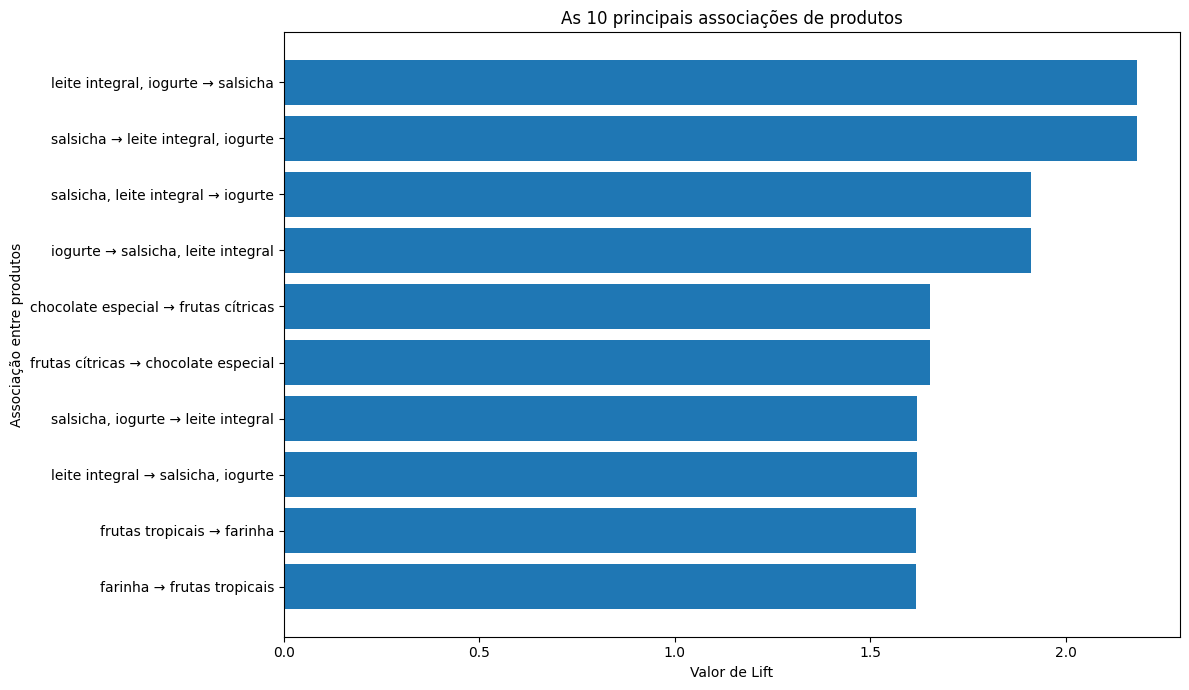

In [11]:
import matplotlib.pyplot as plt

# Selecionar as 10 regras com maior Lift
top_10 = regras_ordenadas.head(10).copy()

# Transformar os conjuntos de produtos em texto
top_10['associacao'] = (
    top_10['antecedents'].apply(lambda x: ', '.join(x))
    + ' → ' +
    top_10['consequents'].apply(lambda x: ', '.join(x))
)

# Criar gráfico
plt.figure(figsize=(12, 7))

plt.barh(
    top_10['associacao'],
    top_10['lift']
)

plt.xlabel('Valor de Lift')
plt.ylabel('Associação entre produtos')
plt.title('As 10 principais associações de produtos')

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [12]:
# Selecionar as 10 melhores associações alternativas
top_alternativas = regras_filtradas.head(10)

print("ANÁLISE DAS ASSOCIAÇÕES ALTERNATIVAS\n")

for _, linha in top_alternativas.iterrows():

    antecedente = ', '.join(linha['antecedents'])
    consequente = ', '.join(linha['consequents'])

    print(f"Produto(s) comprado(s): {antecedente}")
    print(f"Produto(s) associado(s): {consequente}")
    print(f"Suporte: {linha['support']:.4f}")
    print(f"Confiança: {linha['confidence']:.2%}")
    print(f"Lift: {linha['lift']:.2f}")

    if linha['lift'] > 2:
        print("Análise: associação positiva forte entre os produtos.")
    elif linha['lift'] > 1:
        print("Análise: associação positiva entre os produtos.")
    else:
        print("Análise: associação fraca ou negativa.")

    print("-" * 50)

ANÁLISE DAS ASSOCIAÇÕES ALTERNATIVAS

Produto(s) comprado(s): chocolate especial
Produto(s) associado(s): frutas cítricas
Suporte: 0.0014
Confiança: 8.79%
Lift: 1.65
Análise: associação positiva entre os produtos.
--------------------------------------------------
Produto(s) comprado(s): frutas cítricas
Produto(s) associado(s): chocolate especial
Suporte: 0.0014
Confiança: 2.64%
Lift: 1.65
Análise: associação positiva entre os produtos.
--------------------------------------------------
Produto(s) comprado(s): frutas tropicais
Produto(s) associado(s): farinha
Suporte: 0.0011
Confiança: 1.58%
Lift: 1.62
Análise: associação positiva entre os produtos.
--------------------------------------------------
Produto(s) comprado(s): farinha
Produto(s) associado(s): frutas tropicais
Suporte: 0.0011
Confiança: 10.96%
Lift: 1.62
Análise: associação positiva entre os produtos.
--------------------------------------------------
Produto(s) comprado(s): napkins
Produto(s) associado(s): folhados/doces
S